# 02 — Delivery Performance EDA

**Project:** E-Commerce Delivery Performance & Customer Satisfaction  
**Business question:** How long do orders take to reach customers, how variable are delivery durations, and how reliably are estimated delivery dates met?

## Analytical scope
1. Purchase-to-delivery duration (elapsed days).
2. Distribution shape and descriptive statistics.
3. Quartiles, IQR, boxplots, and potential outliers.
4. Exact-timestamp punctuality as a diagnostic comparison.
5. Calendar-date punctuality under an explicit business assumption.

**Important distinction:** Delivery duration is not the same as delivery lateness. A 30-day delivery can still be on time if the estimated delivery date was 40 days after purchase.

Run this notebook from the repository root. Place `olist_orders_dataset.csv` in `data/raw/`.

## 0. Setup and data loading

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

sns.set_theme(style="whitegrid")

# Try common locations used in Jupyter and Google Colab.
candidates = [
    Path("data/raw/olist_orders_dataset.csv"),
    Path("data/raw/olist_orders_dataset.csv"),
    Path("dataset/olist_orders_dataset.csv"),
    Path("olist_orders_dataset.csv"),
    Path("/content/olist_orders_dataset.csv"),
]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Place olist_orders_dataset.csv beside this notebook, in dataset/, "
        "or in /content/ (Colab), then rerun this cell."
    )

# Raw source data: preserve this DataFrame without modifying it.
df = pd.read_csv(DATA_PATH)
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns from {DATA_PATH}")

Loaded 99,441 rows and 8 columns from dataset/olist_orders_dataset.csv


## 4. Challenge 04 — Delivery duration and descriptive statistics

**Business question:** How long does it take for a delivered order to reach the customer?

**Metric definition:** `delivery_days = actual customer delivery timestamp − purchase timestamp`, measured as elapsed days. This is **delivery duration**, not lateness against the estimated delivery date.

Only delivered-status orders with valid purchase and actual-delivery timestamps are eligible. Keep fractional days.

In [2]:
# Convert all relevant timestamps on a working copy. The original df remains unchanged.
orders = df.copy()
timestamp_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in timestamp_cols:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

valid_delivery_mask = (
    orders["order_status"].eq("delivered")
    & orders["order_purchase_timestamp"].notna()
    & orders["order_delivered_customer_date"].notna()
)
delivery_df = orders.loc[valid_delivery_mask].copy()

# total_seconds() returns seconds; divide by 86,400 to express elapsed time in days.
delivery_df["delivery_days"] = (
    delivery_df["order_delivered_customer_date"]
    - delivery_df["order_purchase_timestamp"]
).dt.total_seconds() / 86_400

negative_durations = delivery_df.loc[delivery_df["delivery_days"] < 0].copy()
print(f"Valid delivered orders with both timestamps: {len(delivery_df):,}")
print(f"Negative delivery durations requiring investigation: {len(negative_durations):,}")
display(negative_durations[[
    "order_id", "order_purchase_timestamp",
    "order_delivered_customer_date", "delivery_days"
]].head())

# Do not silently discard invalid durations. This analysis subset excludes negatives
# after reporting them; the original df and delivery_df are retained.
analysis_df = delivery_df.loc[delivery_df["delivery_days"] >= 0].copy()
print(f"Orders included in duration analysis: {len(analysis_df):,}")

Valid delivered orders with both timestamps: 96,470
Negative delivery durations requiring investigation: 0


,order_id,order_purchase_timestamp,order_delivered_customer_date,delivery_days


Orders included in duration analysis: 96,470


In [3]:
# Descriptive statistics are calculated in DAYS.
duration_stats = analysis_df["delivery_days"].describe()
q1_duration = analysis_df["delivery_days"].quantile(0.25)
median_duration = analysis_df["delivery_days"].median()
q3_duration = analysis_df["delivery_days"].quantile(0.75)
iqr_duration = q3_duration - q1_duration

summary = duration_stats.rename("delivery_days").to_frame()
display(summary.round(2))
print(f"Q1: {q1_duration:.2f} days")
print(f"Median: {median_duration:.2f} days")
print(f"Q3: {q3_duration:.2f} days")
print(f"IQR: {iqr_duration:.2f} days")

,delivery_days
count,96470.00
mean,12.56
std,9.55
min,0.53
25%,6.77
50%,10.22
75%,15.72
max,209.63


Q1: 6.77 days
Median: 10.22 days
Q3: 15.72 days
IQR: 8.95 days


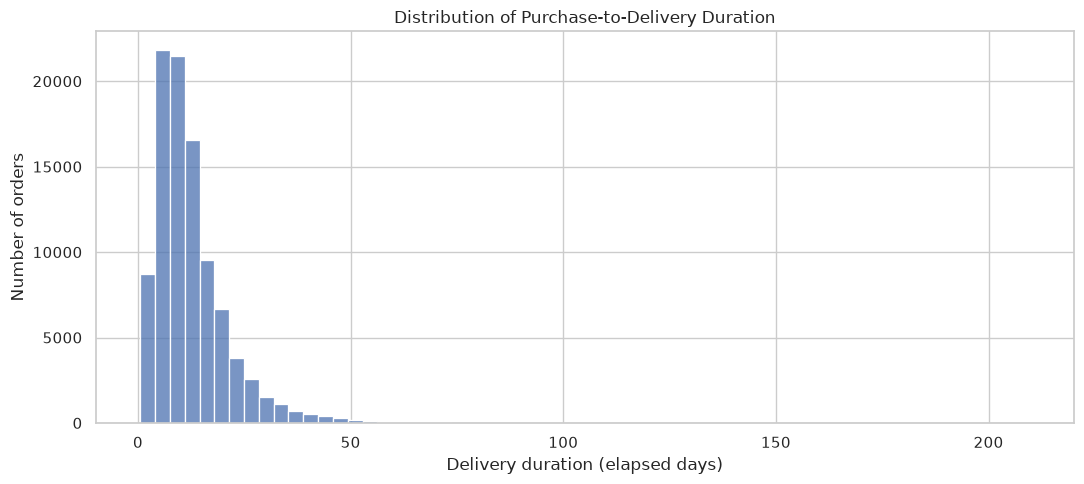

In [4]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.histplot(data=analysis_df, x="delivery_days", bins=60, ax=ax)
ax.set_title("Distribution of Purchase-to-Delivery Duration")
ax.set_xlabel("Delivery duration (elapsed days)")
ax.set_ylabel("Number of orders")
plt.tight_layout()
plt.show()

### Interpretation — Challenge 04

The earlier notebook run reported **96,470 valid delivered orders** in the duration analysis:

- Mean delivery duration: **12.56 days**
- Median delivery duration: **10.22 days**
- Standard deviation: **9.55 days**
- Q1: **6.77 days**
- Q3: **15.72 days**
- IQR: **8.95 days**
- Minimum: **0.53 days**
- Maximum: **209.63 days**

The mean is greater than the median, which is consistent with a right-skewed distribution: some very long deliveries pull the mean upward. Confirm the shape using the histogram rather than relying only on mean-versus-median.

The standard deviation describes spread in the same unit (days). A standard deviation of 9.55 days indicates substantial variation relative to the 12.56-day mean; it does not mean every order is 9.55 days away from the mean.

**Business interpretation:** The median is a useful description of a typical delivery duration in a right-skewed distribution, while the mean remains useful for understanding the arithmetic average and the impact of long-duration orders.

## 5. Challenge 05 — Boxplot, IQR fences, and outlier investigation

**Business question:** Which purchase-to-delivery durations are unusually long relative to the observed distribution?

The 1.5 × IQR rule flags observations below/above the fences. A flagged duration is not automatically an error, and it does not necessarily mean the order was late relative to its promise.

In [5]:
# Quartiles and conventional Tukey fences.
q1_duration = analysis_df["delivery_days"].quantile(0.25)
median_duration = analysis_df["delivery_days"].median()
q3_duration = analysis_df["delivery_days"].quantile(0.75)
iqr_duration = q3_duration - q1_duration
lower_fence = q1_duration - 1.5 * iqr_duration
upper_fence = q3_duration + 1.5 * iqr_duration

print(f"Q1: {q1_duration:.2f} days | Median: {median_duration:.2f} days | Q3: {q3_duration:.2f} days")
print(f"IQR: {iqr_duration:.2f} days")
print(f"Lower fence: {lower_fence:.2f} days")
print(f"Upper fence: {upper_fence:.2f} days")

# Flag outliers without deleting them from analysis_df.
is_outlier = ~analysis_df["delivery_days"].between(lower_fence, upper_fence)
duration_outliers = analysis_df.loc[is_outlier].copy()
outlier_pct = len(duration_outliers) / len(analysis_df) * 100
print(f"Flagged duration outliers: {len(duration_outliers):,}/{len(analysis_df):,} ({outlier_pct:.2f}%)")

# Inspect the five longest observed delivery durations.
longest_five = analysis_df.nlargest(5, "delivery_days")[[
    "order_id", "order_status", "delivery_days",
    "order_purchase_timestamp", "order_delivered_customer_date"
]]
display(longest_five)

Q1: 6.77 days | Median: 10.22 days | Q3: 15.72 days
IQR: 8.95 days
Lower fence: -6.66 days
Upper fence: 29.15 days
Flagged duration outliers: 4,896/96,470 (5.08%)


,order_id,order_status,delivery_days,order_purchase_timestamp,order_delivered_customer_date
19590,ca07593549f1816d26a572e06dc1eab6,delivered,209.628611,2017-02-21 23:31:27,2017-09-19 14:36:39
55619,1b3190b2dfa9d789e1f14c05b647a14a,delivered,208.351759,2018-02-23 14:57:35,2018-09-19 23:24:07
61610,440d0d17af552815d15a9e41abe49359,delivered,195.634016,2017-03-07 23:59:51,2017-09-19 15:12:50
70307,2fb597c2f772eca01b1f5c561bf6cc7b,delivered,194.850174,2017-03-08 18:09:02,2017-09-19 14:33:17
89130,285ab9426d6982034523a855f55a885e,delivered,194.633611,2017-03-08 22:47:40,2017-09-19 14:00:04


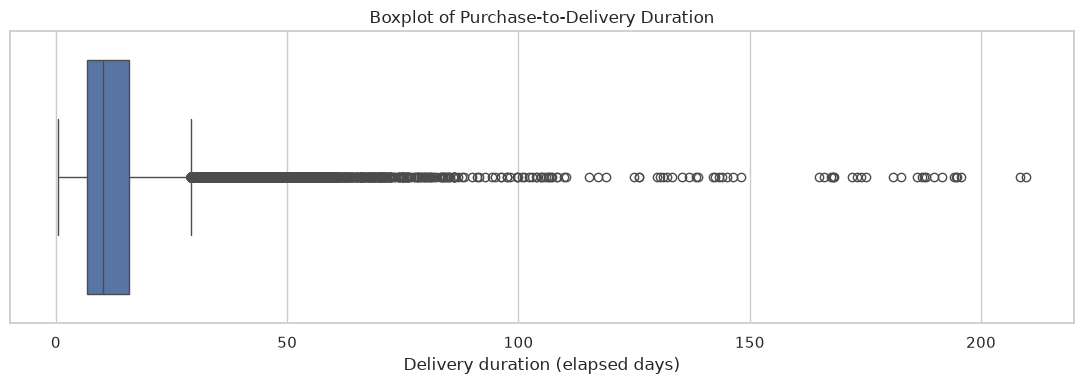

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=analysis_df, x="delivery_days", ax=ax)
ax.set_title("Boxplot of Purchase-to-Delivery Duration")
ax.set_xlabel("Delivery duration (elapsed days)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### Interpretation — Challenge 05

The earlier run reported Q1 = **6.77 days**, Q3 = **15.72 days**, and IQR = **8.95 days**. Therefore, the middle 50% of delivery durations spans approximately 8.95 days, from Q1 to Q3.

The earlier notebook reported **5.08%** of valid delivered orders outside the 1.5 × IQR fences. Re-run this notebook to confirm the count and percentage. The lower fence is below zero for these quartiles, while observed durations are positive, so flagged observations are expected to be on the upper side.

Your conclusion that a very long delivery should be audited rather than automatically removed is correct. An order taking 150 days could be a genuine service failure, a data issue, or an unusual but real case. Compare its actual delivery date with its estimated delivery date before calling it late.

**Important distinction:** A duration outlier answers “Was the purchase-to-arrival duration unusually long?” It does not answer “Did the order arrive after the promised date?”

## 6. Challenge 06 — Exact timestamp punctuality (diagnostic comparison)

**Business question:** What happens if we compare the exact actual-delivery timestamp to the estimated-delivery timestamp?

This is a diagnostic calculation only. If the estimated field represents a promised **calendar date** rather than a precise deadline at midnight, an order delivered later on that same date should not automatically be called late.

In [7]:
# Build a punctuality sample requiring delivered status and valid actual + estimated dates.
punctuality_mask = (
    orders["order_status"].eq("delivered")
    & orders["order_delivered_customer_date"].notna()
    & orders["order_estimated_delivery_date"].notna()
)
punctuality_df = orders.loc[punctuality_mask].copy()

# Exact timestamp difference in fractional days; positive means actual timestamp is later.
punctuality_df["timestamp_delay_days"] = (
    punctuality_df["order_delivered_customer_date"]
    - punctuality_df["order_estimated_delivery_date"]
).dt.total_seconds() / 86_400

exact_counts = pd.Series({
    "Early": punctuality_df["timestamp_delay_days"].lt(0).sum(),
    "Exact on-time": punctuality_df["timestamp_delay_days"].eq(0).sum(),
    "Late": punctuality_df["timestamp_delay_days"].gt(0).sum(),
}, name="orders")
exact_summary = exact_counts.to_frame()
exact_summary["pct"] = exact_summary["orders"] / len(punctuality_df) * 100
print(f"Valid delivered orders with actual and estimated timestamps: {len(punctuality_df):,}")
display(exact_summary.round(2))

Valid delivered orders with actual and estimated timestamps: 96,470


,orders,pct
Early,88644,91.89
Exact on-time,0,0.00
Late,7826,8.11


### Interpretation — Challenge 06

In the earlier notebook, exact timestamp comparison classified **91.89%** as early, **0%** as exactly on time, and **8.11%** as late. The zero exact-on-time rate is a warning that the estimate is date-based while the actual field includes a time-of-day component.

For example, if the estimated date is March 15 at 00:00 and the order arrives March 15 at 16:30, the exact timestamp difference is positive even though the order arrived on the promised calendar date. Therefore, the exact timestamp method may overstate lateness when the business promise is a date, not a time-of-day deadline.

## 7. Challenge 07 — Calendar-date punctuality KPI

**Business assumption:** The estimated delivery field represents a promise to deliver **by the end of the stated calendar date**. Under this assumption:
- Actual date before estimated date = Early
- Actual date equal to estimated date = On time
- Actual date after estimated date = Late

If the business contract instead defines a precise time deadline, use that deadline. Document the chosen definition in any portfolio or management report.

In [8]:
# Normalize sets the time component to midnight while preserving the calendar date.
punctuality_df["actual_delivery_date"] = punctuality_df["order_delivered_customer_date"].dt.normalize()
punctuality_df["estimated_delivery_date"] = punctuality_df["order_estimated_delivery_date"].dt.normalize()

# Integer calendar-day difference: negative = early, zero = on time, positive = late.
punctuality_df["calendar_delay_days"] = (
    punctuality_df["actual_delivery_date"] - punctuality_df["estimated_delivery_date"]
).dt.days

conditions = [
    punctuality_df["calendar_delay_days"].lt(0),
    punctuality_df["calendar_delay_days"].eq(0),
    punctuality_df["calendar_delay_days"].gt(0),
]
punctuality_df["delivery_class"] = np.select(
    conditions, ["Early", "On time", "Late"], default="Unclassified"
)

calendar_counts = punctuality_df["delivery_class"].value_counts().reindex(
    ["Early", "On time", "Late"], fill_value=0
)
calendar_summary = calendar_counts.rename("orders").to_frame()
calendar_summary["pct"] = calendar_summary["orders"] / len(punctuality_df) * 100

# QA checks: every eligible order should be assigned exactly one class.
assert calendar_summary["orders"].sum() == len(punctuality_df)
assert punctuality_df["delivery_class"].ne("Unclassified").all()
assert np.isclose(calendar_summary["pct"].sum(), 100.0)

print("Calendar-date delivery performance:")
display(calendar_summary.round(2))

# Compare timestamp-based and calendar-date definitions in percentage points.
# Align indices: map "Exact on-time" to "On time" for comparison
exact_aligned = exact_summary.copy()
exact_aligned.index = exact_aligned.index.str.replace("Exact on-time", "On time")

comparison = pd.DataFrame({
    "exact_timestamp_pct": exact_aligned["pct"],
    "calendar_date_pct": calendar_summary["pct"],
})
comparison["change_percentage_points"] = (
    comparison["calendar_date_pct"] - comparison["exact_timestamp_pct"]
)
comparison.index = ["Early", "On time", "Late"]
display(comparison.round(2))


Calendar-date delivery performance:


,orders,pct
delivery_class,,
Early,88644,91.89
On time,1292,1.34
Late,6534,6.77


ValueError: Length mismatch: Expected axis has 4 elements, new values have 3 elements

In [ ]:
# Chart 1: count of orders by calendar-date delivery class.
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=calendar_summary.index, y=calendar_summary["orders"], ax=ax)
ax.set_title("Orders by Calendar-Date Delivery Classification")
ax.set_xlabel("Delivery classification")
ax.set_ylabel("Number of orders")
plt.tight_layout()
plt.show()

# Chart 2: spread of calendar days early/late. The vertical line marks the promised date.
fig, ax = plt.subplots(figsize=(11, 4))
sns.boxplot(data=punctuality_df, x="calendar_delay_days", ax=ax)
ax.axvline(0, color="darkred", linestyle="--", label="Promised calendar date")
ax.set_title("Calendar Days Early or Late")
ax.set_xlabel("Calendar delay (days; negative = early, positive = late)")
ax.set_ylabel("")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Automatically generate a concise interpretation from the calculated results.
late_pct = calendar_summary.loc["Late", "pct"]
on_time_pct = calendar_summary.loc["On time", "pct"]
early_pct = calendar_summary.loc["Early", "pct"]
late_count = calendar_summary.loc["Late", "orders"]

print(f"{early_pct:.2f}% of eligible delivered orders arrived before the estimated calendar date.")
print(f"{on_time_pct:.2f}% arrived on the estimated calendar date.")
print(f"{late_pct:.2f}% arrived after the estimated calendar date ({late_count:,} orders).")
print("Interpretation: the calendar-date definition counts deliveries made at any time on the estimated date as on time.")
print("Business caution: assess how many days late orders were, not only the late percentage.")

### Interpretation — Calendar-date punctuality

Run the preceding cells to generate the calendar-date early, on-time, and late percentages from the CSV.

**Do not hard-code a result from an earlier run.** The previously reported 6.77% late rate was not independently verified from saved output. Use the freshly generated `calendar_summary` table as the source of truth.

**Business assumption:** This notebook treats the estimated delivery field as a promise to deliver by the end of the stated calendar date. Confirm this interpretation against the business definition before publishing the KPI.

## 8. Portfolio-ready executive summary (complete after rerunning)

Use this structure in your GitHub README or project report. Replace bracketed fields with the results generated by your own run.

### Objective
Evaluated order-level delivery duration and punctuality using the Olist Brazilian E-Commerce orders dataset.

### Method
Inspected data quality and missingness; calculated elapsed purchase-to-delivery duration; summarized the distribution using mean, median, standard deviation, quartiles, and IQR; flagged potential duration outliers using the 1.5 × IQR rule; and compared exact-timestamp punctuality with a calendar-date definition.

### Key findings
- Analyzed **[N]** delivered orders with valid purchase and actual delivery timestamps.
- Median purchase-to-delivery duration: **[X] days**; mean: **[Y] days**.
- **[Z]%** of valid duration observations were flagged as potential IQR outliers; these were retained for investigation rather than automatically removed.
- Calendar-date late-delivery rate: **[L]%**, using the explicit assumption that delivery is due by the end of the estimated date.

### Business implications
Use the calendar-date KPI only if it matches the actual delivery promise. Investigate late-order severity and segment-level patterns before setting a performance target. Do not claim causation or a performance improvement from descriptive statistics alone.

### Next analysis
Join order-level punctuality results to the Olist review table using `order_id`, validate the join cardinality, and investigate whether review scores differ across early, on-time, and late groups. Then choose a statistical test based on the outcome scale, assumptions, and research question.

## 9. Reproducibility and final checks

Before publishing:
- [ ] Run all cells from top to bottom with the original Olist orders CSV.
- [ ] Confirm `order_id` uniqueness and record the dataset row count.
- [ ] Confirm all delivery durations are in **days**, not seconds.
- [ ] Keep the denominator explicit for every percentage.
- [ ] Confirm the calendar-date definition matches the business promise.
- [ ] Replace all bracketed values in the executive summary with fresh results.
- [ ] Save the executed notebook and include a short README explaining the data source and limitations.